In [ ]:

!pip install openmeteo-requests
!pip install requests-cache retry-requests numpy pandas
!pip install rasterio


get distribution of points that correspond to population density

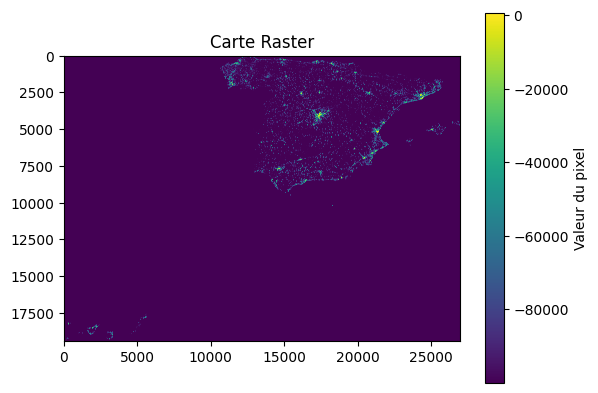

In [1]:

import rasterio
import matplotlib.pyplot as plt
import os

os.chdir("C:\\Users\\DBT3KD\\Downloads")

# Lire le fichier .tif
file_path = 'esp_ppp_2020_UNadj_constrained.tif'  # Remplace avec ton chemin
with rasterio.open(file_path) as src:
    raster = src.read(1)  # Lit la première couche (band)
    profile = src.profile  # Métadonnées (projection, résolution, etc.)
    bounds = src.bounds
    transform = src.transform

# Afficher le raster
plt.imshow(raster, cmap='viridis')
plt.title("Carte Raster")
plt.colorbar(label="Valeur du pixel")
plt.show()


In [2]:
import numpy as np
import pandas as pd
# 1. Aplatir le raster en un vecteur
flat_raster = raster.flatten()

# 2. Nettoyer : remplacer valeurs invalides ou négatives par 0
flat_raster[flat_raster < 0] = 0
total_pop = flat_raster.sum()
if total_pop == 0:
    raise ValueError("La population totale est nulle après nettoyage. Vérifie le raster.")

# 3. Probabilités d’échantillonnage
probs = flat_raster / total_pop

# 4. Échantillonnage d’indices
indices = np.random.choice(len(flat_raster), size=1000, replace=True, p=probs)

# 5. Convertir indices en lignes / colonnes de la grille
rows, cols = np.unravel_index(indices, raster.shape)

# 6. Convertir en coordonnées géographiques (longitude, latitude)
with rasterio.open(file_path) as src:
    lons, lats = rasterio.transform.xy(transform, rows, cols)

# 7. Construire un DataFrame
df = pd.DataFrame({'longitude': lons, 'latitude': lats})

# 8. Sauvegarde ou affichage
#df.to_csv('points_population_espagne.csv', index=False)
print(df.head())

   longitude   latitude
0   4.272500  39.882500
1  -0.330000  39.446667
2   2.803333  41.968333
3  -1.978333  38.648333
4  -1.050000  38.111667


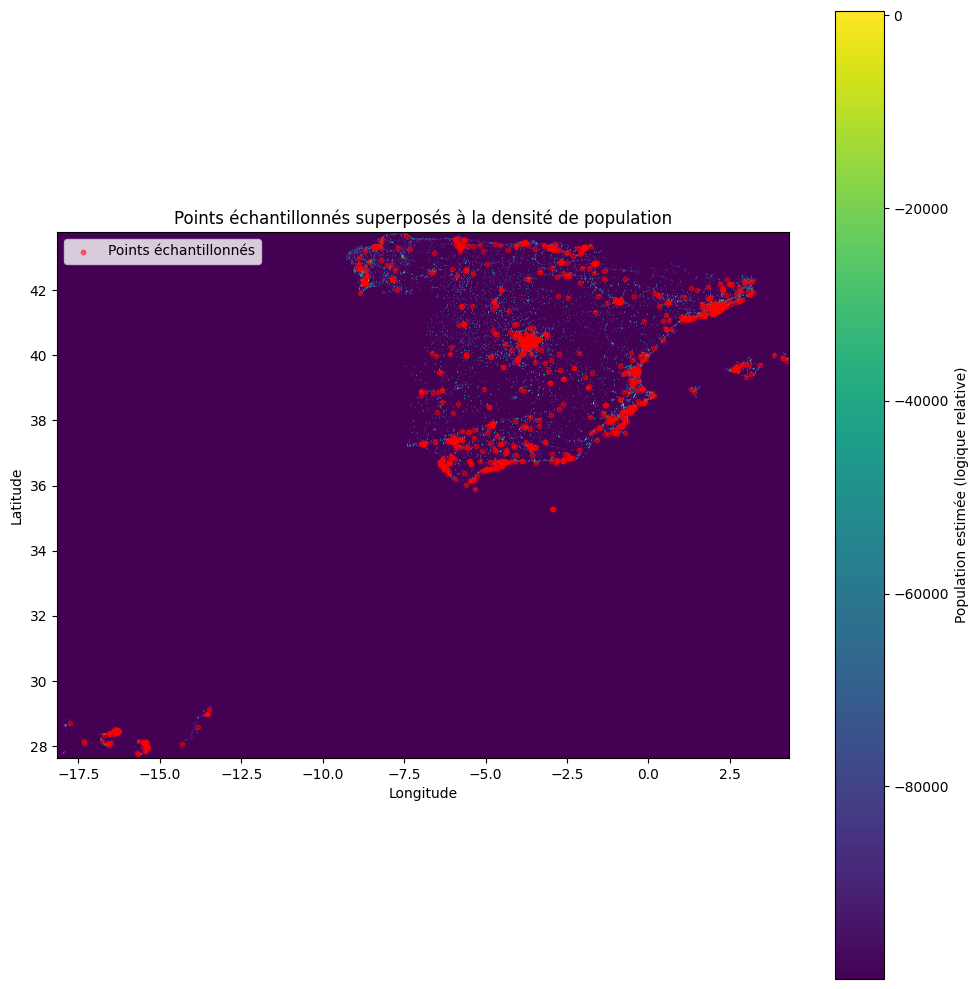

In [7]:
# --- Tracer ---
plt.figure(figsize=(10, 10))

# Affichage du raster
plt.imshow(raster, cmap='viridis', extent=[bounds.left, bounds.right, bounds.bottom, bounds.top])
plt.colorbar(label='Population estimée (logique relative)')


# Affichage des points
plt.scatter(lons, lats, s=10, c='red', alpha=0.5, label='Points échantillonnés')

# Mise en forme
plt.title("Points échantillonnés superposés à la densité de population")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.tight_layout()

plt.show()

In [ ]:
import openmeteo_requests
import pandas as pd
import requests_cache
from retry_requests import retry
import time

# Configuration Open-Meteo
cache_session = requests_cache.CachedSession('.cache', expire_after=-1)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)

# Période d'intérêt
start_date = "2015-01-01"
end_date = "2023-12-31"

# Liste pour stocker les résultats
all_data = []

# Boucle sur les points
for idx, row in df.iterrows():
    lat = row["latitude"]
    lon = row["longitude"]
    
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": ["temperature_2m", "relative_humidity_2m", "precipitation"]
    }
    

    # ... à insérer dans ta boucle sur les points
    success = False
    while not success:
        try:
            responses = openmeteo.weather_api("https://archive-api.open-meteo.com/v1/archive", params=params)
            response = responses[0]

            hourly = response.Hourly()
            time_index = pd.date_range(
                start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                freq=pd.Timedelta(seconds=hourly.Interval()),
                inclusive="left"
            )

            data = {
                "latitude": lat,
                "longitude": lon,
                "date": time_index,
                "temperature_2m": hourly.Variables(0).ValuesAsNumpy(),
                "relative_humidity_2m": hourly.Variables(1).ValuesAsNumpy(),
                "precipitation": hourly.Variables(2).ValuesAsNumpy()
            }

            df_point = pd.DataFrame(data)
            all_data.append(df_point)

            print(f"✅ Fini pour point {idx+1}/{len(df)} ({lat}, {lon})")

            time.sleep(5)  # Facultatif : pour réduire la pression sur l'API

            success = True  # Sortie de boucle si réussite

        except Exception as e:
            # Gérer l'erreur de quota (limite API)
            if hasattr(e, 'args') and len(e.args) > 0 and 'request limit exceeded' in str(e.args[0]).lower():
                print(f"⏳ Limite de requêtes atteinte pour ({lat}, {lon}). Attente de 60 secondes...")
                time.sleep(60)
            else:
                print(f"⚠️ Échec pour le point {idx+1}/{len(df)} ({lat}, {lon}): {e}")
                success = True  # Ne pas boucler indéfiniment pour d'autres types d'erreurs


# Concaténer les résultats
full_df = pd.concat(all_data, ignore_index=True)
full_df.head(5)

✅ Fini pour point 1/1000 (40.59416670520022, -3.705833304062823)
✅ Fini pour point 2/1000 (39.60666670917345, 2.679166670292137)
✅ Fini pour point 3/1000 (36.76416672061031, -2.621666641750659)
✅ Fini pour point 4/1000 (41.121666703077814, 1.2091666761963182)
✅ Fini pour point 5/1000 (40.49500003893256, -3.8783333033699865)
✅ Fini pour point 6/1000 (43.569166693230244, -5.923333295156343)
✅ Fini pour point 7/1000 (36.64083338777321, -4.6691666335269755)
✅ Fini pour point 8/1000 (28.118333422063678, -15.424166590330044)
✅ Fini pour point 9/1000 (41.4158333685609, -4.785833299725057)
✅ Fini pour point 10/1000 (41.389166702001525, 2.152500005740798)
✅ Fini pour point 11/1000 (39.48166670967639, -0.37999998408753655)
✅ Fini pour point 12/1000 (41.64750003429545, -4.7274999666260165)
✅ Fini pour point 13/1000 (38.88000004543054, -0.5941666498940137)
✅ Fini pour point 14/1000 (36.721666720781315, -4.450833301070567)
✅ Fini pour point 15/1000 (36.40000005540888, -5.654999962900758)
✅ Fini pou

In [ ]:
os.chdir("C:\\Users\\DBT3KD\\Downloads")
df.to_csv('points_population_espagne.csv', index=False)
full_df.to_csv("meteo_espagne_points.csv", index=False)
print("✅ Tous les points traités et exportés.")